# 01 - Waymo Open Motion Dataset: Exploration & Tabular Extraction

**Project:** Machine Learning-Based Tactical Decision Prediction for Autonomous Driving  
**Phase:** 1 - Dataset Exploration, Protobuf Decoding, and Quality Auditing  
**Dataset:** Waymo Open Motion Dataset - Local 2-shard development sample


## 1. Setup & Environment
Load project modules and dependencies.


In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from src.data.tfrecord_reader import discover_tfrecords, get_dataset_metadata, iter_scenarios
from src.data.scenario_parser import ScenarioParser
from src.preprocessing.preprocessing import run_full_quality_audit
from src.data.dataset_exporter import DatasetExporter


## 2. Dataset Discovery
Identify local TFRecord shards and display file properties.


In [2]:
metadata = get_dataset_metadata()
print(f"Discovered {metadata['file_count']} files in {metadata['directory']}:")
for f in metadata['files']:
    print(f"  - {f['filename']}: {f['size_mb']} MB ({f['bytes']:,} bytes)")
print(f"Total dataset size: {metadata['total_mb']} MB")


Discovered 2 files in data/raw:
  - training_20s.tfrecord-00000-of-01000: 90.2 MB (94,580,752 bytes)
  - training_20s.tfrecord-00001-of-01000: 93.67 MB (98,219,608 bytes)
Total dataset size: 183.87 MB


## 3. Streaming and Decoding Scenarios
Stream and decode up to 100 scenarios with TensorFlow and Protobuf.


In [3]:
scenarios = list(iter_scenarios(max_scenarios=100))
print(f"Successfully decoded {len(scenarios)} scenarios.")


Successfully decoded 100 scenarios.


I0000 00:00:1795200417.440630 5370563 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


## 4. Extracting Tabular DataFrames
Transform protobuf data into scenario summary, object states, and ego kinematics DataFrames.


In [4]:
parser = ScenarioParser(nearby_radius=50.0)
summary_df, objects_df, ego_df = parser.parse_scenarios(scenarios)

print("Summary shape:", summary_df.shape)
print("Objects shape:", objects_df.shape)
print("Ego shape:    ", ego_df.shape)


Summary shape: (100, 19)
Objects shape: (8998, 15)
Ego shape:     (100, 10)


In [5]:
summary_df.head()


,scenario_id,timestamps_count,current_time_index,num_tracks,num_vehicles,num_pedestrians,num_cyclists,num_other,num_map_features,num_dynamic_map_states,ego_valid,sdc_track_index,num_lanes,num_road_edges,num_road_lines,num_crosswalks,num_speed_bumps,num_stop_signs,num_driveways
0,41600af30ab8cc55,198,0,54,52,1,1,0,217,198,True,53,123,18,47,5,2,1,21
1,2aa43fad083efbf3,198,0,204,191,13,0,0,195,198,True,203,116,15,34,6,1,1,22
2,eb073968f66914c7,198,0,139,137,2,0,0,571,198,True,138,400,73,49,10,13,6,20
3,cebdf28156152fd6,198,0,31,31,0,0,0,203,198,True,30,105,32,6,2,3,1,54
4,e2030d66ebfe7b6b,200,0,60,50,10,0,0,153,200,True,59,80,26,17,5,2,3,20


In [6]:
objects_df[objects_df['valid']].head(10)


,scenario_id,object_id,object_type,is_ego,x,y,z,velocity_x,velocity_y,speed,heading,length,width,height,valid
0,41600af30ab8cc55,128,VEHICLE,False,8427.785156,700.940979,-134.722137,-0.039062,-5.219727,5.219873,-1.575415,4.337318,1.973674,1.511271,True
1,41600af30ab8cc55,129,VEHICLE,False,8439.434570,600.367859,-134.897263,0.146484,3.019409,3.022960,1.537734,4.520164,2.072741,1.639223,True
2,41600af30ab8cc55,130,VEHICLE,False,8431.082031,719.897583,-134.468262,0.029297,-7.604980,7.605037,-1.564991,4.628398,2.153799,1.671876,True
3,41600af30ab8cc55,131,VEHICLE,False,8424.414062,716.243958,-134.538864,0.117188,-9.340210,9.340945,-1.555790,4.436041,1.969507,1.615200,True
4,41600af30ab8cc55,132,VEHICLE,False,8445.657227,721.193481,-134.277130,-1.425781,7.229004,7.368266,-4.639013,4.924515,2.212290,1.921697,True
6,41600af30ab8cc55,134,VEHICLE,False,8380.546875,650.405701,-134.661804,0.000000,0.000000,0.000000,1.664413,4.460143,2.003505,1.604215,True
29,41600af30ab8cc55,878,PEDESTRIAN,False,8409.705078,651.977966,-134.547729,0.493164,0.572815,0.755862,-1.587239,0.780693,0.765131,1.745893,True
30,41600af30ab8cc55,105,VEHICLE,False,8428.181641,660.322998,-134.630661,0.000000,0.000000,0.000000,-1.562478,4.565321,2.064912,1.640030,True
31,41600af30ab8cc55,106,VEHICLE,False,8431.624023,668.443665,-134.590958,-0.009766,-2.312012,2.312032,-1.584020,4.526225,2.103710,1.572131,True
32,41600af30ab8cc55,107,VEHICLE,False,8428.707031,652.090820,-134.526352,0.000000,0.000000,0.000000,-1.539289,4.701671,2.113555,1.651599,True


In [7]:
ego_df.head()


,scenario_id,ego_x,ego_y,ego_speed,ego_velocity_x,ego_velocity_y,ego_heading,nearby_vehicle_count,nearby_pedestrian_count,nearby_cyclist_count
0,41600af30ab8cc55,8431.891618,654.179487,0.347826,0.002161,-0.347820,-1.559338,21,1,0
1,2aa43fad083efbf3,132.915330,718.157978,0.000932,-0.000292,0.000885,2.592125,51,1,0
2,eb073968f66914c7,8399.978644,3069.303176,0.000906,-0.000712,-0.000561,0.010258,28,1,0
3,cebdf28156152fd6,-5561.456915,7941.420198,9.602272,9.601521,-0.120022,-0.011476,2,0,0
4,e2030d66ebfe7b6b,-813.201241,-727.875966,8.357167,-5.932070,5.886662,2.371684,15,0,0


## 5. Automated Data Quality Audit
Verify data integrity: no duplicates, no negative/infinite speeds, and full ego validity.


In [8]:
audit = run_full_quality_audit(summary_df, objects_df, ego_df)
print(f"Quality audit passed: {audit['overall_passed']}")
print("Summary audit: ", audit['summary_quality'])
print("Objects audit: ", audit['objects_quality'])
print("Ego audit:     ", audit['ego_quality'])


Quality audit passed: True
Summary audit:  {'total_scenarios': 100, 'duplicate_scenario_ids': 0, 'nan_counts': {}, 'ego_valid_count': 100, 'ego_valid_percentage': 100.0, 'passed': True}
Objects audit:  {'total_records': 8998, 'valid_records': 2867, 'duplicate_object_ids_in_scenario': 0, 'negative_speeds': 0, 'infinite_speeds': 0, 'excessive_speeds_gt_80ms': 0, 'valid_records_with_nan_coords': 0, 'min_speed_ms': 0.0, 'max_speed_ms': 27.72424499822173, 'mean_speed_ms': 2.798327846768972, 'passed': True}
Ego audit:      {'total_records': 100, 'nan_speeds': 0, 'negative_speeds': 0, 'infinite_speeds': 0, 'min_ego_speed_ms': 0.00016041955049228093, 'max_ego_speed_ms': 20.210337237248446, 'mean_ego_speed_ms': 5.016490415648523, 'passed': True}


## 6. Temporal Information Inspection (PAST -> CURRENT -> FUTURE)
Inspect timeline length and temporal structure of scenarios.


In [9]:
sample_sc = scenarios[0]
sdc = sample_sc.tracks[sample_sc.sdc_track_index]
total_steps = len(sdc.states)
curr_idx = sample_sc.current_time_index if sample_sc.current_time_index is not None else 0

print(f"Scenario ID: {sample_sc.scenario_id}")
print(f"Total timestamps: {total_steps} (~{total_steps*0.1:.1f} s at 10Hz)")
print(f"Current index:    {curr_idx}")
print(f"Past horizon:     {curr_idx} steps ({curr_idx*0.1:.1f} s)")
print(f"Future horizon:   {total_steps - curr_idx - 1} steps ({(total_steps - curr_idx - 1)*0.1:.1f} s)")


Scenario ID: 41600af30ab8cc55
Total timestamps: 198 (~19.8 s at 10Hz)
Current index:    0
Past horizon:     0 steps (0.0 s)
Future horizon:   197 steps (19.7 s)


## 7. HD Vector Map Element Counts
Examine lanes, boundaries, crosswalks, and traffic controls.


In [10]:
map_counts = {
    'Lanes': summary_df['num_lanes'].sum(),
    'Road Edges': summary_df['num_road_edges'].sum(),
    'Road Lines': summary_df['num_road_lines'].sum(),
    'Crosswalks': summary_df['num_crosswalks'].sum(),
    'Speed Bumps': summary_df['num_speed_bumps'].sum(),
    'Stop Signs': summary_df['num_stop_signs'].sum(),
    'Driveways': summary_df['num_driveways'].sum()
}
print("Map feature breakdown:", map_counts)


Map feature breakdown: {'Lanes': np.int64(19754), 'Road Edges': np.int64(4109), 'Road Lines': np.int64(3700), 'Crosswalks': np.int64(768), 'Speed Bumps': np.int64(485), 'Stop Signs': np.int64(345), 'Driveways': np.int64(2805)}


## 8. Exploratory Visualizations
Generate figures and render bird's-eye-view top-down scene.


In [11]:
exporter = DatasetExporter(PROJECT_ROOT / 'outputs')
fig_paths = exporter.generate_figures(summary_df, objects_df, scenarios=scenarios)
for name, p in fig_paths.items():
    print(f"Exported figure: {name} -> {p}")


Exported figure: object_distribution -> outputs/figures/object_distribution.png
Exported figure: speed_distribution -> outputs/figures/speed_distribution.png
Exported figure: objects_per_scenario -> outputs/figures/objects_per_scenario.png
Exported figure: topdown_scenario -> outputs/figures/topdown_scenario.png


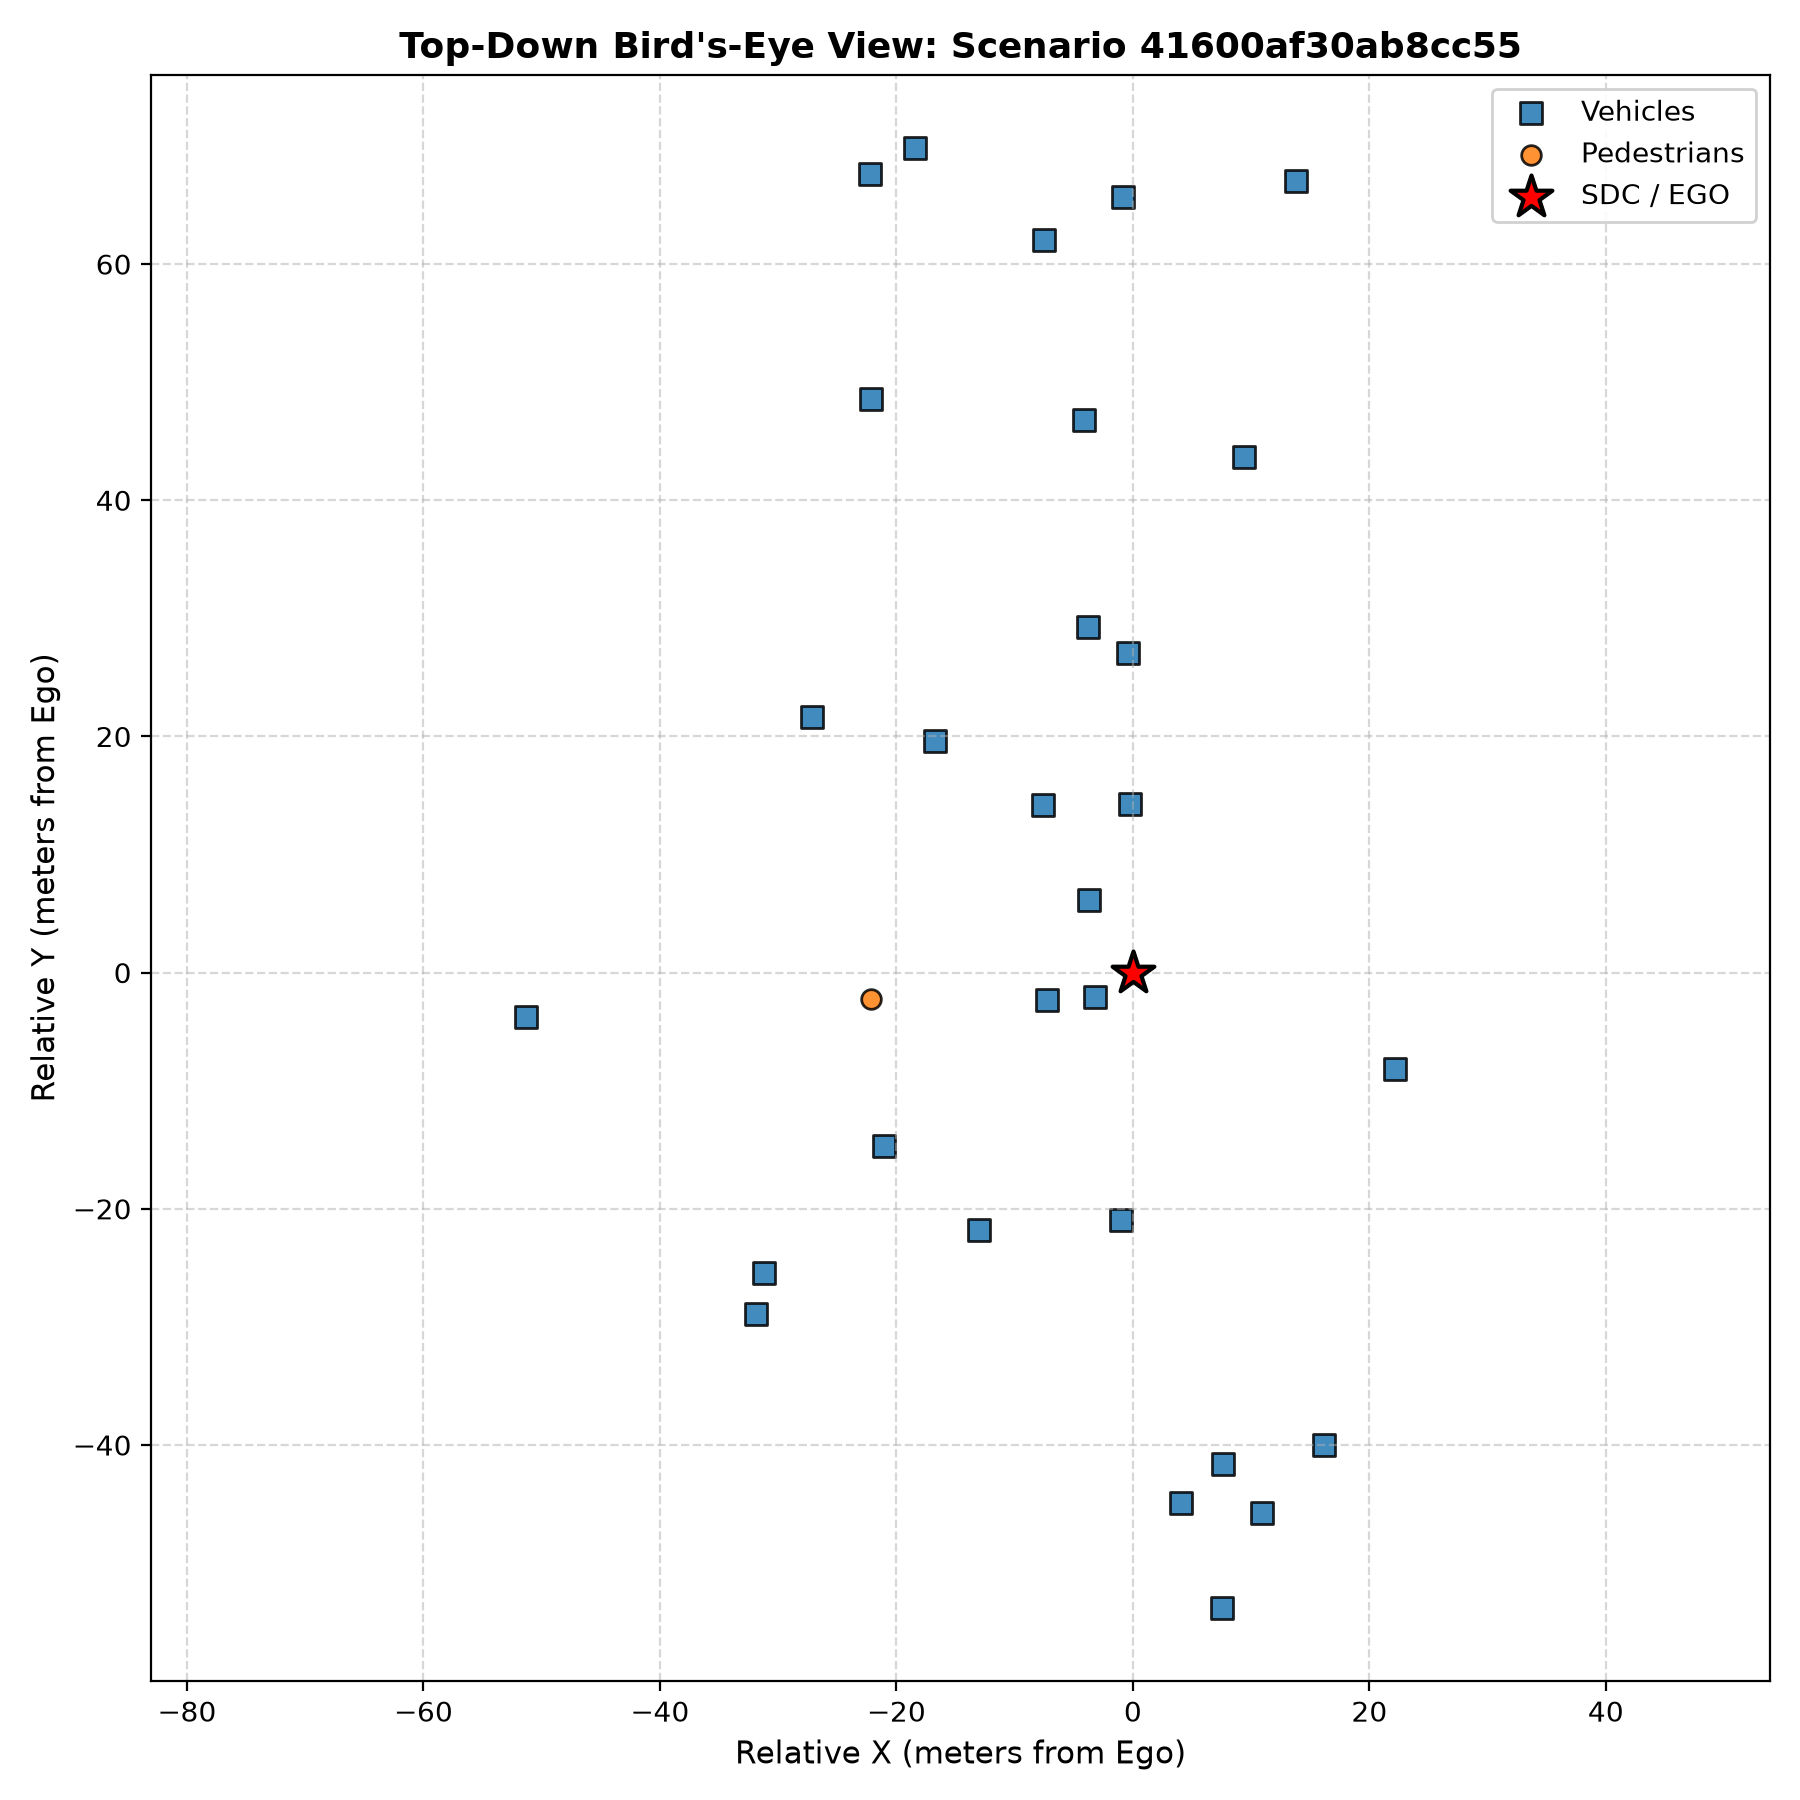

In [12]:
from IPython.display import Image, display
display(Image(filename=fig_paths['topdown_scenario']))


## 9. Next Steps: Phase 2 Preparation
Phase 1 dataset exploration and tabular extraction is complete and verified.
Phase 2 will proceed with Target Engineering, Feature Engineering, and class distribution analysis.
